<a href="https://colab.research.google.com/github/olusolayemi/networks-communities/blob/main/Flow_or_proximity%3F_Upstream_aggregation%2C_not_channel_connectivity%2C_structures_river_reach_classifications_across_Canada_JoH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Paper 1 pipeline on Google Colab
**Flow or proximity? Upstream aggregation, not channel connectivity, structures river-reach classifications across Canada**

**Runtime:** about 50–70 minutes with `N_PERM = 999` (the published setting). Use `N_PERM = 99` for a 15-minute trial run.

## 1. Settings

In [1]:
N_PERM = 999          # shuffles for Result 1 (999 = published; 99 = quick trial)
USE_DRIVE = True      # keep everything in Google Drive (recommended)
WORK = "/content/drive/MyDrive/paper1_rivers" if USE_DRIVE else "/content/paper1_rivers"
GLORIC_URL = "https://data.hydrosheds.org/file/hydrosheds-associated/gloric/GloRiC_Canada_v10_shapefile.zip"

## 2. Connect Google Drive and create the work folder
A pop-up asks you to allow access to your Drive the first time.

In [2]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
print("Working in:", os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/paper1_rivers


## 3. Put the pipeline package in place
Either copy `paper1_pipeline.zip` into the Drive folder `MyDrive/paper1_rivers/` beforehand, or run this cell and pick the file when the upload button appears.

In [3]:
if not os.path.exists("run_paper1.sh"):
    if not os.path.exists("paper1_pipeline.zip"):
        if IN_COLAB:
            from google.colab import files
            print("Choose paper1_pipeline.zip ...")
            up = files.upload()
            name = list(up)[0]
            if name != "paper1_pipeline.zip":
                os.rename(name, "paper1_pipeline.zip")
        else:
            raise FileNotFoundError("Put paper1_pipeline.zip in " + WORK)
    !unzip -q -o paper1_pipeline.zip
!ls

build_companion.py  gloric	      paper1_pipeline.zip  run_paper1.sh
companion	    map_companion.py  paper1_results.zip   src
data		    map_grid.py       README.md		   styles
figure_style.yaml   out		      requirements.txt


## 4. Install packages
Colab already has most of them; this adds the rest (about 1 minute).

In [4]:
!pip install -q -r requirements.txt
import geopandas, pyogrio, sklearn, statsmodels, rdata
print("packages ready")

packages ready


## 5. Download GloRiC-Canada (47 MB)

In [5]:
SHP = os.path.join(WORK, "gloric/GloRiC_Canada_v10_shapefile/GloRiC_Canada_v10.shp")
if not os.path.exists(SHP):
    os.makedirs("gloric", exist_ok=True)
    !wget -q -O gloric/gloric.zip "$GLORIC_URL"
    !unzip -q -o gloric/gloric.zip -d gloric
!find gloric -name "*.shp"
assert os.path.exists(SHP), "Shapefile not found - check the find output above and fix the SHP path"
print("GloRiC ready:", SHP)

gloric/GloRiC_Canada_v10_shapefile/GloRiC_Canada_v10.shp
GloRiC ready: /content/drive/MyDrive/paper1_rivers/gloric/GloRiC_Canada_v10_shapefile/GloRiC_Canada_v10.shp


## 6. Run the pipeline, one step per cell
Each cell prints its progress. If Colab disconnects, re-run cells 1–2, then continue from the step that stopped (earlier outputs are kept in Drive).

**6a. Boundaries, lakes and HYDAT station list** (downloads, under 1 minute)

In [6]:
!python src/00_get_boundaries.py
!python src/p1_get_stations.py

provinces and 41 large lakes written
stations file ready


**6b. Network, Strahler order, river systems, drainage regions, basin units** (about 1 minute)

In [7]:
!python src/01_prepare.py "$SHP" 2>&1 | grep -v -i warning

reaches in Canada: 570920
Strahler range: 1 9
reaches routed through large lakes: 18182
catchment-area columns carried through: none (supply --area-file to p1_circularity.py)
                      reaches  systems
region                                
Arctic                 155049     6439
Atlantic               124564     3908
Gulf of Mexico           1480       56
Hudson Bay             198333     2988
Interior (endorheic)     9705      867
Pacific                 81789     3659
prov
QC    113957
ON     55342
MB     30985
SK       319
NL       250
NU       163
NB        61
Name: count, dtype: int64
units by province (>= 30 reaches):
unit_prov
MB    118
ON    177
QC    402
Name: unit, dtype: int64
reaches in those units: 163503 of 203041


**6c. Result 1 – organisation beyond stream size, by drainage region** (longest step: about 15–20 min at 999 shuffles)

In [8]:
!python -u src/02_analysis.py $N_PERM data/reaches_canada.parquet region _region

reaches analysed: 457517, units: 2092
flow links 455425, sibling pairs 233803, confluences 225656
Class_hydr: 8 types, 151s
Class_phys: 10 types, 151s
Class_geom: 6 types, 151s
Kmeans_23: 23 types, 149s
Glob_type: 55 types, 151s
done


**6d. Result 4 – landscape controls with river-system block bootstrap** (under 1 minute)

In [9]:
!python src/07_block_bootstrap.py _region 2>&1 | grep -v -i warning

scheme        HC3 (independent basins)  grid 250 km  grid 500 km  river system
term                                                                          
lake_pc_s                          1.0          1.0          1.0           1.0
log_n_s                            0.0          0.0          0.0           0.0
log_relief_s                       1.0          1.0          1.0           1.0
log_spow_s                         1.0          1.0          1.0           1.0
peat_pc_s                          1.0          1.0          1.0           1.0
temp_av_s                          0.0          0.0          0.0           0.0
        term                   scheme   coef     lo     hi  n_blocks
     log_n_s HC3 (independent basins)  0.000 -0.005  0.006      2063
   lake_pc_s HC3 (independent basins) -0.021 -0.028 -0.013      2063
   peat_pc_s HC3 (independent basins)  0.038  0.027  0.050      2063
  log_spow_s HC3 (independent basins) -0.018 -0.026 -0.009      2063
   temp_av_s HC3 (indep

**6e. Result 2 – flow vs sibling vs aggregation (circularity tests)** (about 10–15 min)

In [11]:
!python -u src/p1_circularity.py | cut -c1-160

Observed geomorphic class [{'group': 'Arctic', 'flow_excess': 0.15, 'sib_excess': 0.094, 'gap': 0.056}, {'group': 'Atlantic', 'flow_excess': 0.115, 'sib_excess'
Observed hydrologic class [{'group': 'Arctic', 'flow_excess': 0.129, 'sib_excess': 0.074, 'gap': 0.055}, {'group': 'Atlantic', 'flow_excess': 0.104, 'sib_excess
Observed physio-climatic class (local inputs) [{'group': 'Arctic', 'flow_excess': 0.109, 'sib_excess': 0.119, 'gap': -0.009}, {'group': 'Atlantic', 'flow_excess
Local gradient sextiles [{'group': 'Arctic', 'flow_excess': 0.095, 'sib_excess': 0.1, 'gap': -0.005}, {'group': 'Atlantic', 'flow_excess': 0.048, 'sib_excess': 
Local k-means (gradient, peat) [{'group': 'Arctic', 'flow_excess': 0.178, 'sib_excess': 0.193, 'gap': -0.015}, {'group': 'Atlantic', 'flow_excess': 0.141, 'sib_
Area weighting needs a catchment-area column: give --area-file/--area-col, or --weight length.accumulation null: weight = area, 720 block orders x 10 realisations x 2 variants



**6f. Result 3 – gauging-network representation** (about 2 minutes)

In [12]:
!python src/p1_monitoring.py data/allstations.rda "$SHP" 2>&1 | grep -v -i warn

represented-neighbourhood radius (links): {'Arctic': 4, 'Atlantic': 3, 'Gulf of Mexico': 2, 'Hudson Bay': 4, 'Interior (endorheic)': 3, 'Pacific': 3}
stations snapped: 7696 active: 2816
              region        km  km_active  km_ever  pct_active  pct_ever  ell_links  stations_active  stations_ever
              Arctic 765699.38   17241.78 27948.28        2.25      3.65          4              366            741
            Atlantic 464782.58   21815.21 38456.02        4.69      8.27          3              897           2230
      Gulf of Mexico   7297.42    1100.53  2317.13       15.08     31.75          2               64            199
          Hudson Bay 943530.47   40735.38 65510.18        4.32      6.94          4              958           2086
Interior (endorheic)  46231.35    1528.42  3645.52        3.31      7.89          3               49            179
             Pacific 274181.41   10954.92 29377.73        4.00     10.71          3              482           2261
re

**6g. Robustness – trunk threshold and minimum basin size** (about 10–15 min)

In [13]:
!python -u src/p1_sensitivity.py | cut -c1-160

100 30 Class_geom 2817 [['Arctic', 0.136, 0.056, 3.411], ['Atlantic', 0.105, 0.042, 3.114], ['Gulf of Mexico', 0.087, 0.099, 2.098], ['Hudson Bay', 0.129, 0.028
100 30 Class_hydr 2817 [['Arctic', 0.108, 0.05, 2.522], ['Atlantic', 0.092, 0.057, 1.864], ['Gulf of Mexico', 0.16, 0.112, 2.9], ['Hudson Bay', 0.085, 0.056, 2.
100 30 Class_phys 2817 [['Arctic', 0.081, -0.009, nan], ['Atlantic', 0.096, -0.009, 5.276], ['Gulf of Mexico', 0.061, 0.01, 4.531], ['Hudson Bay', 0.064, -0.005
100 100 Class_geom 1157 [['Arctic', 0.148, 0.058, 3.642], ['Atlantic', 0.108, 0.044, 3.246], ['Gulf of Mexico', 0.096, 0.108, 1.984], ['Hudson Bay', 0.139, 0.03
100 100 Class_hydr 1157 [['Arctic', 0.117, 0.054, 2.543], ['Atlantic', 0.099, 0.059, 1.891], ['Gulf of Mexico', 0.202, 0.129, 3.087], ['Hudson Bay', 0.091, 0.05
100 100 Class_phys 1157 [['Arctic', 0.094, -0.01, nan], ['Atlantic', 0.102, -0.009, 6.174], ['Gulf of Mexico', 0.086, 0.013, 4.296], ['Hudson Bay', 0.069, -0.00
300 30 Class_geom 2092 [['Arctic',

**6h. Figures**

In [14]:
!python src/p1_figures.py 2>&1 | grep -v -i warn
!ls out/figs

fig1_concept_map: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
fig2_organisation_by_region: 10.0 in wide; base font prints at ~7.5 pt at 190 mm
fig3_flow_proximity_aggregation: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
fig4_correlation_length: 16.0 in wide; base font prints at ~4.7 pt at 190 mm
fig5_monitoring_representation: 14.0 in wide; base font prints at ~5.3 pt at 190 mm
fig6_landscape_drivers: 9.0 in wide; base font prints at ~8.3 pt at 190 mm
figS1_sensitivity: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
figS2_drainage_regions: 11.0 in wide; base font prints at ~6.8 pt at 190 mm
done
P1_fig1_concept_map.pdf			P1_fig5_monitoring_representation.pdf
P1_fig1_concept_map.png			P1_fig5_monitoring_representation.png
P1_fig2_organisation_by_region.pdf	P1_fig6_landscape_drivers.pdf
P1_fig2_organisation_by_region.png	P1_fig6_landscape_drivers.png
P1_fig3_flow_proximity_aggregation.pdf	P1_figS1_sensitivity.pdf
P1_fig3_flow_proximity_aggregation.png	P1_figS1_sensit

## 6i. Customise the figures (optional, about 1 minute per redraw)
All appearance settings are in **`figure_style.yaml`** in your Drive folder. Edit them in either of two ways:

**Option A – edit the file directly.** In the Colab left sidebar, open the folder icon, go to `drive/MyDrive/paper1_rivers/`, double-click `figure_style.yaml`, edit it and save (Ctrl+S). Then run the redraw cell below.

**Option B – set the most common options in the next cell.** It updates `figure_style.yaml` for you.

Ready-made styles: `styles/default.yaml` (report look) and `styles/journal_print.yaml` (white, panel letters only, colour-blind-safe colours, PDF + 600-dpi TIFF).

In [15]:
import yaml
st = yaml.safe_load(open("figure_style.yaml"))

# ---- change anything below, then run this cell and the redraw cell ----
st["font"]["family"] = "DejaVu Sans"        # e.g. "Arial" if installed
st["font"]["size"] = 10                     # raise to ~14 for print-size text (see the printed pt values)
st["show_titles"] = False                    # False = panel letters only
st["panel_letter_style"] = "{L}  "          # "({l})" gives (a), (b)
st["colors"]["background"] = "#fcfcfb"      # "#ffffff" for pure white
st["output"]["formats"] = ["png", "pdf"]    # add "tiff" or "svg" if needed
st["output"]["dpi"] = 300
st["regions"]["colors"].update({            # drainage-region colours
    "Hudson Bay": "#2a78d6", "Atlantic": "#eb6834", "Arctic": "#1baf7a", "Pacific": "#eda100"})
st["regions"]["shown"] = ["Hudson Bay", "Arctic", "Atlantic", "Pacific"]   # add "Gulf of Mexico", "Interior (endorheic)"
# ------------------------------------------------------------------------
yaml.safe_dump(st, open("figure_style.yaml", "w"), allow_unicode=True, sort_keys=False)
print("figure_style.yaml updated")

figure_style.yaml updated


**Redraw** – all figures, or name some (e.g. `fig3 fig5`). To use a preset instead: `--style styles/journal_print.yaml`.

In [16]:
WHICH = ""            # "" = all, or e.g. "fig3 fig5"
STYLE = "figure_style.yaml"   # or "styles/journal_print.yaml"
!python src/p1_figures.py --style $STYLE $WHICH 2>&1 | grep -v -i warn

fig1_concept_map: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
fig2_organisation_by_region: 10.0 in wide; base font prints at ~7.5 pt at 190 mm
fig3_flow_proximity_aggregation: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
fig4_correlation_length: 16.0 in wide; base font prints at ~4.7 pt at 190 mm
fig5_monitoring_representation: 14.0 in wide; base font prints at ~5.3 pt at 190 mm
fig6_landscape_drivers: 9.0 in wide; base font prints at ~8.3 pt at 190 mm
figS1_sensitivity: 15.0 in wide; base font prints at ~5.0 pt at 190 mm
figS2_drainage_regions: 11.0 in wide; base font prints at ~6.8 pt at 190 mm
done


## 7. Look at the figures

out/figs/P1_fig1_concept_map.png


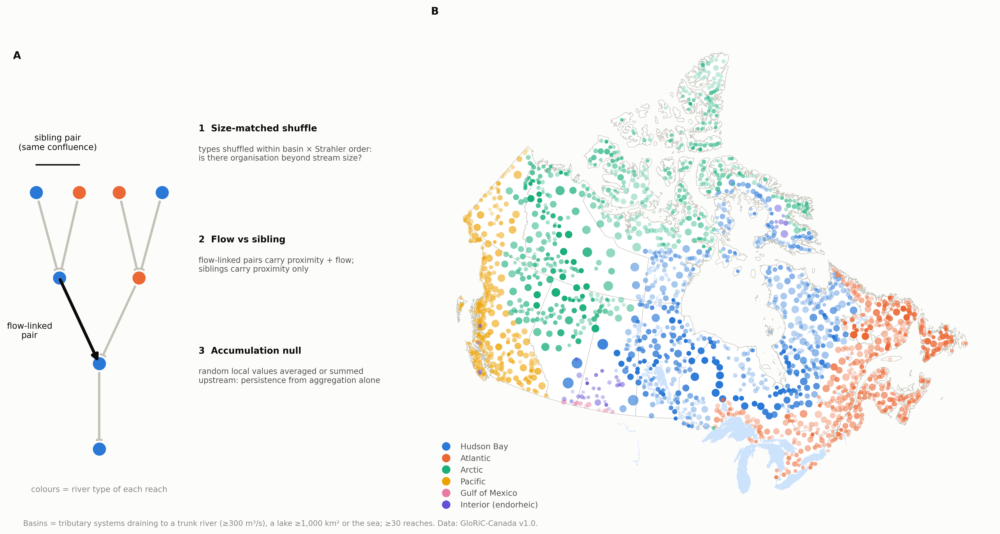

out/figs/P1_fig2_organisation_by_region.png


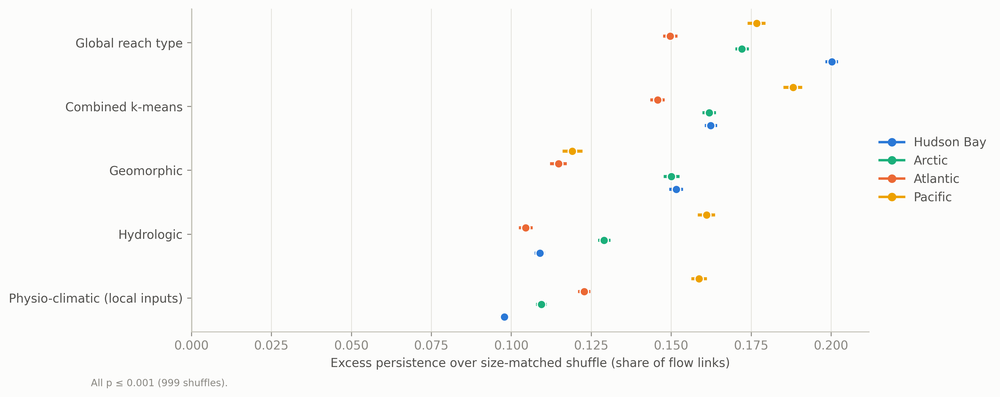

out/figs/P1_fig3_flow_proximity_aggregation.png


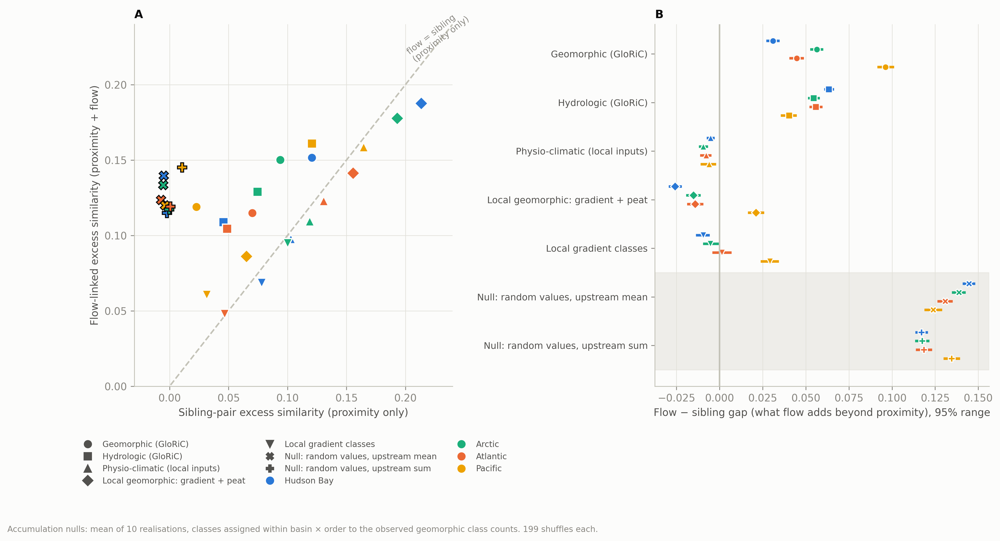

out/figs/P1_fig4_correlation_length.png


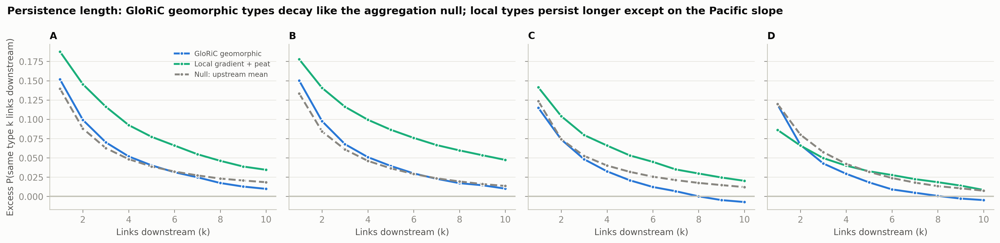

out/figs/P1_fig5_monitoring_representation.png


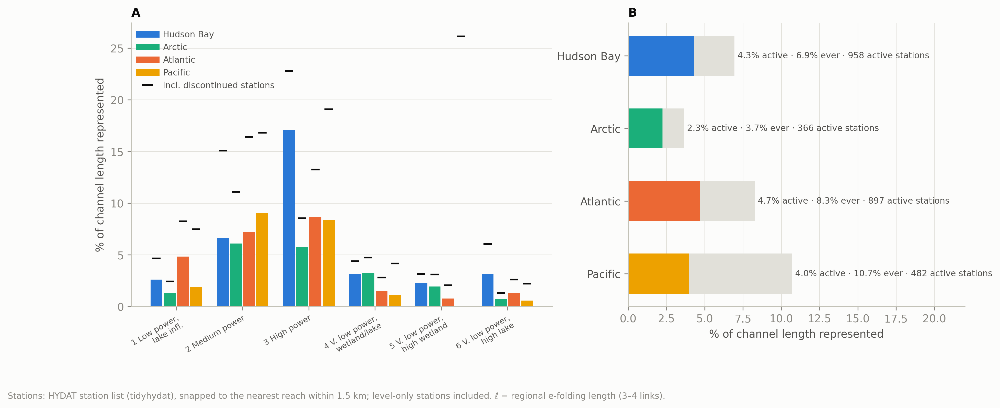

out/figs/P1_fig6_landscape_drivers.png


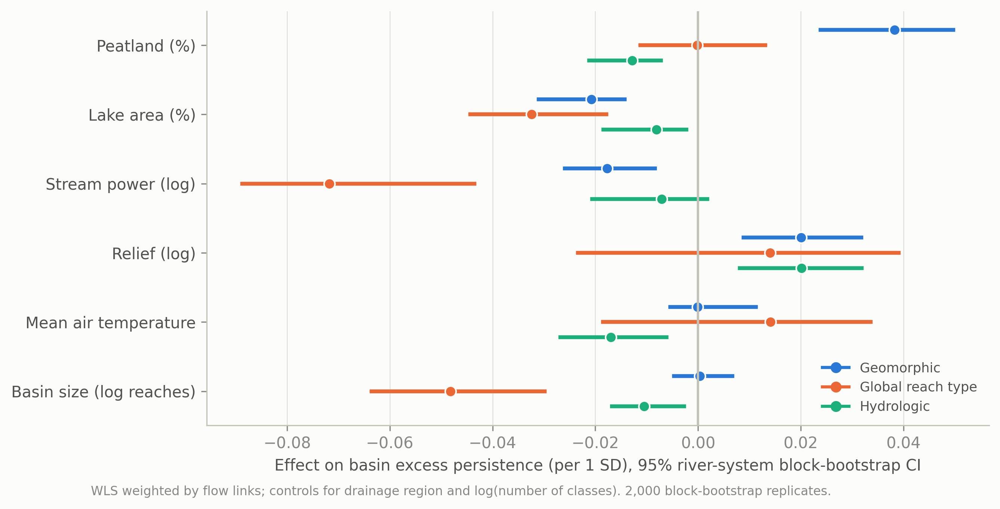

out/figs/P1_figS1_sensitivity.png


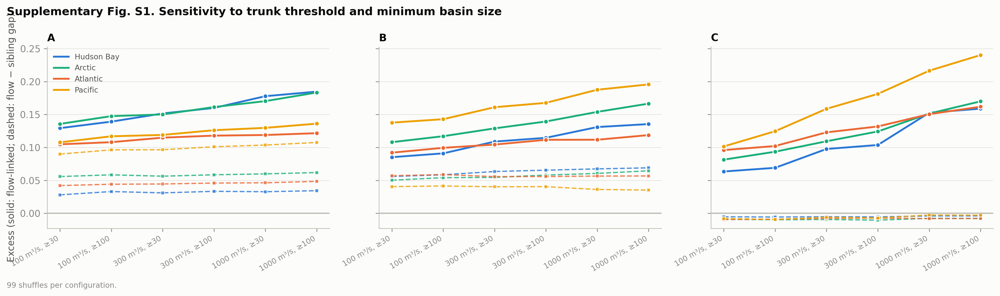

out/figs/P1_figS2_drainage_regions.png


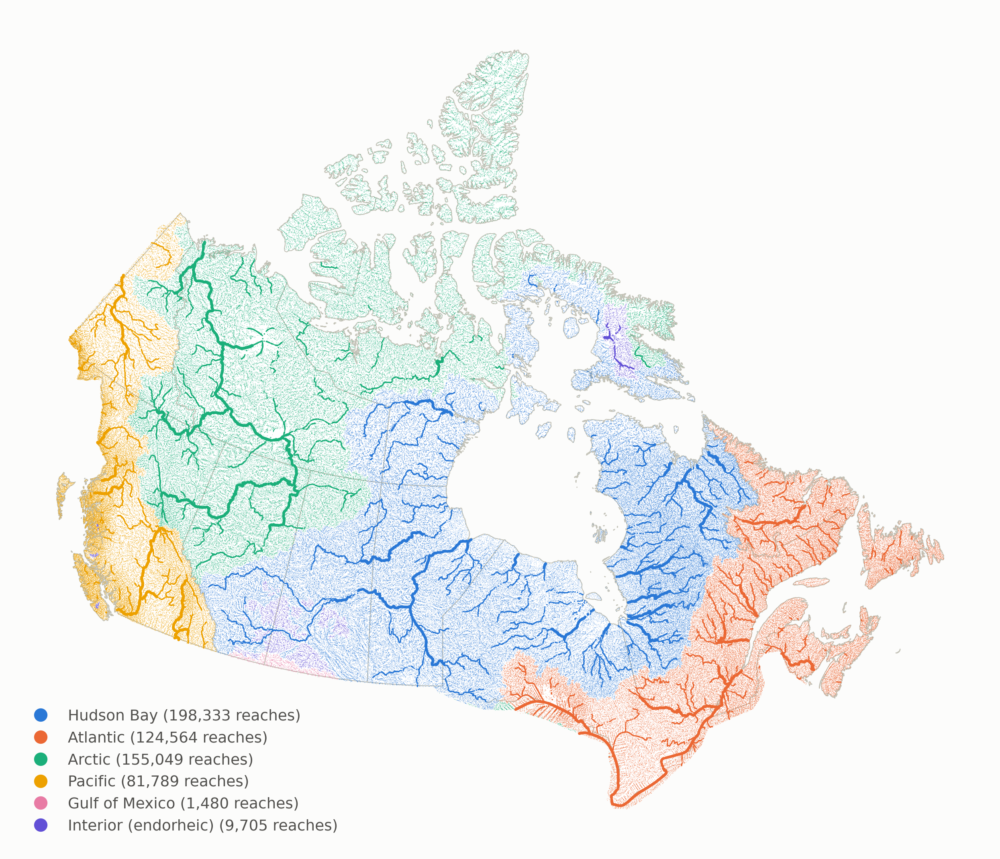

In [17]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("out/figs/P1_*.png")):
    print(f); display(Image(f, width=1100))

## 8. Key numbers at a glance

In [18]:
import pandas as pd
pd.set_option("display.width", 200)
c = pd.read_csv("out/tables/p1_circularity.csv")
c["test"] = c.test.str.replace(r" #\d+", "", regex=True)
major = ["Hudson Bay", "Arctic", "Atlantic", "Pacific"]
print("Flow-linked excess, sibling excess and gap (mean over realisations):")
display(c[c.group.isin(major)].groupby(["test", "group"])[["flow_excess", "sib_excess", "gap", "efold"]].mean().round(3))
display(pd.read_csv("out/tables/p1_monitoring_by_region.csv").round(2))

Flow-linked excess, sibling excess and gap (mean over realisations):


flow_excess  sib_excess    gap  efold
test                                          group                                            
Accumulation null: upstream mean              Arctic            0.133      -0.005  0.139  3.798
                                              Atlantic          0.124      -0.007  0.131  3.569
                                              Hudson Bay        0.140      -0.005  0.145  3.786
                                              Pacific           0.120      -0.004  0.124  3.878
Accumulation null: upstream sum               Arctic            0.117      -0.000  0.118  3.110
                                              Atlantic          0.119       0.001  0.118  2.530
                                              Hudson Bay        0.115      -0.002  0.117  3.927
                                              Pacific           0.145       0.011  0.135  2.357
Local gradient sextiles                       Arctic            0.095       0.100 -0.005  4.127
                                              Atlantic          0.048       0.047  0.001  3.592
                                              Hudson Bay        0.069       0.078 -0.009  4.806
                                              Pacific           0.061       0.031  0.029  2.553
Local k-means (gradient, peat)                Arctic            0.178       0.193 -0.015  7.171
                                              Atlantic          0.141       0.155 -0.014  5.128
                                              Hudson Bay        0.188       0.213 -0.026  5.729
                                              Pacific           0.086       0.065  0.021  5.183
Observed geomorphic class                     Arctic            0.150       0.094  0.056  3.743
                                              Atlantic          0.115       0.070  0.045  3.378
                                              Hudson Bay        0.152       0.121  0.031  3.784
                                              Pacific           0.119       0.023  0.096  2.955
Observed hydrologic class                     Arctic            0.129       0.074  0.055  2.733
                                              Atlantic          0.104       0.049  0.056  1.931
                                              Hudson Bay        0.109       0.046  0.063  2.853
                                              Pacific           0.161       0.121  0.040  2.110
Observed physio-climatic class (local inputs) Arctic            0.109       0.119 -0.009    NaN
                                              Atlantic          0.123       0.131 -0.008  7.453
                                              Hudson Bay        0.098       0.103 -0.005    NaN
                                              Pacific           0.159       0.165 -0.006    NaN

,region,km,km_active,km_ever,pct_active,pct_ever,ell_links,stations_active,stations_ever
0,Arctic,765699.38,17241.78,27948.28,2.25,3.65,4,366,741
1,Atlantic,464782.58,21815.21,38456.02,4.69,8.27,3,897,2230
2,Gulf of Mexico,7297.42,1100.53,2317.13,15.08,31.75,2,64,199
3,Hudson Bay,943530.47,40735.38,65510.18,4.32,6.94,4,958,2086
4,Interior (endorheic),46231.35,1528.42,3645.52,3.31,7.89,3,49,179
5,Pacific,274181.41,10954.92,29377.73,4.00,10.71,3,482,2261


## 9. Download the results
Creates `paper1_results.zip` (tables + figures). It is also saved in your Drive folder.

In [19]:
!zip -q -r paper1_results.zip out/tables out/figs
if IN_COLAB:
    from google.colab import files
    files.download("paper1_results.zip")
print("saved:", os.path.join(WORK, "paper1_results.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved: /content/drive/MyDrive/paper1_rivers/paper1_results.zip


### Troubleshooting
- **Disconnected mid-run:** re-run cells 1–2 (settings, Drive), skip 3–5 if the files are already there, and continue from the step that stopped.
- **`wget` fails in step 5:** download the shapefile zip in your browser from the HydroSHEDS GloRiC page, put it in `MyDrive/paper1_rivers/gloric/` as `gloric.zip`, and re-run step 5.
- **Faster trial:** set `N_PERM = 99` in step 1. The circularity and sensitivity steps already use 199 and 99 shuffles.
- **Numbers differ slightly from the report:** only if `N_PERM` differs; with 999 the results match the report exactly (fixed random seed).